# P3 — Analyse de la pollution de l'air (OpenAQ, 55 stations, 12 villes, 5 ans)

**Source** : couche silver `silver/pollution/` (Parquet dans Silo) — 3,46 M mesures station × polluant × heure UTC
(98,7 % valides), du 01/11/2021 au 31/10/2026 ; stations de référence des réseaux officiels (EEA France).

**Référence sanitaire** : lignes directrices de l'**OMS (2021)** — moyenne annuelle : PM2.5 5 µg/m³, PM10 15,
NO2 10 ; moyenne 24 h : PM2.5 15, PM10 45, NO2 25, CO 4 000 ; O3 : maximum journalier de la moyenne sur 8 h, 100.

Seules les mesures valides sont utilisées ; un jour n'est retenu que s'il compte **au moins 18 h de mesure**.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common.storage import get_storage
from common.silver import read_silver, read_table
from common import viz
from p3_pollution import analytics as a

viz.apply_style()
pd.set_option("display.width", 160)
s = get_storage()
d = a.valid(read_silver(s, "silver/pollution/", filename="pollution_heure.parquet"))
stations = read_table(s, "silver/pollution/stations.parquet")
st = a.station_stats(d, stations)
cday = a.city_daily(a.daily(d))
print(f"{len(d):,} mesures valides · {d['station_id'].nunique()} stations · {len(cday):,} jours ville × polluant")

3,419,782 mesures valides · 55 stations · 56,783 jours ville × polluant


## Q1 — Zones les plus polluées

**Méthode** : moyenne et percentile 95 des mesures horaires par station (stations avec au moins 2 000 heures de
mesure) ; moyenne de la ville = moyenne de ses stations. Le **type de station** (trafic / fond urbain) est
**déduit du nom** (« périphérique », « A7 », « Proxi », « boulevard »…) : OpenAQ ne fournit pas ce champ, c'est une
approximation.

polluant,co,no2,o3,pm10,pm25
ville_id,,,,,
bordeaux,NaN,14.9,54.7,17.0,9.2
clermont-ferrand,NaN,12.2,55.8,12.8,7.0
lille,194.8,14.8,52.5,16.5,10.4
lyon,229.5,25.2,46.0,19.7,10.5
marseille,262.2,24.0,54.2,17.9,9.3
montpellier,NaN,27.2,58.3,20.3,10.4
nantes,299.4,13.3,57.4,16.3,8.7
paris,199.5,27.4,50.5,20.5,10.5
rennes,NaN,15.0,58.6,15.2,8.6


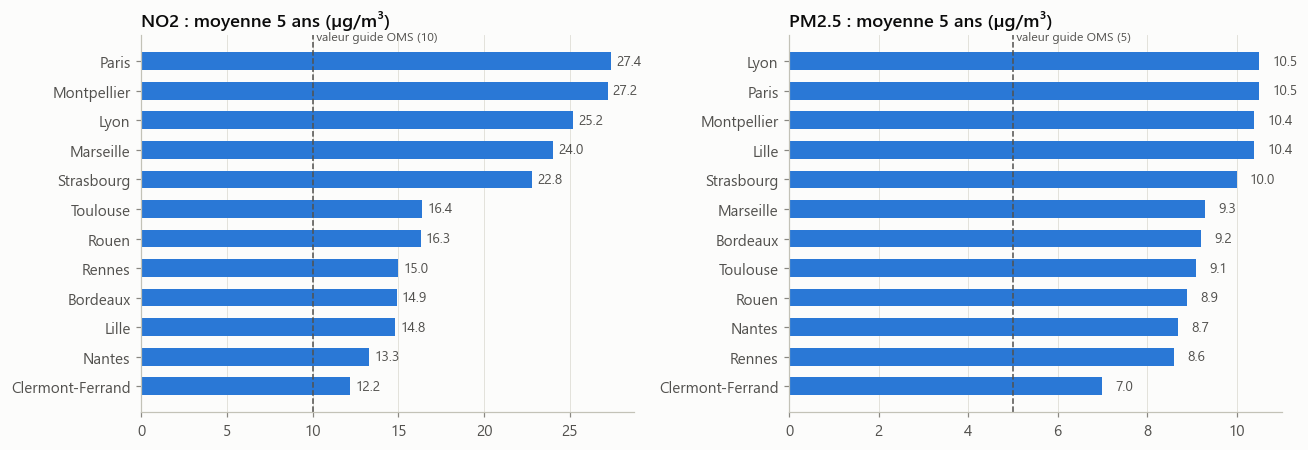

Stations les plus exposées — NO2 :


,ville_id,station_nom,type,moyenne,p95
0,paris,Bld peripherique Est,trafic,43.9,82.8
1,lyon,Lyon Périphérique,trafic,42.9,83.5
2,montpellier,Montpellier Liberté,fond urbain,42.4,87.2
3,montpellier,Montpellier Antigone,fond urbain,35.3,83.9
4,strasbourg,Strasbourg A35 Remparts,trafic,34.1,66.2
5,lyon,A7 SUD LYONNAIS,trafic,33.3,69.5


Stations les plus exposées — PM2.5 :


,ville_id,station_nom,type,moyenne,p95
0,paris,Bld peripherique Est,trafic,12.7,28.1
1,lille,Roubaix Serres,fond urbain,12.0,31.1
2,lyon,A7 SUD LYONNAIS,trafic,11.9,30.6
3,montpellier,Montpellier Liberté,fond urbain,11.9,23.4
4,paris,PARIS 1er Les Halles,fond urbain,10.8,25.7
5,lyon,LYON Centre,fond urbain,10.7,28.9


NO2 moyen par type de station : {'fond urbain': 17.1, 'trafic': 35.1}


In [2]:
cm = a.city_means(st)
display(cm)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, p, who in ((axes[0], "no2", 10), (axes[1], "pm25", 5)):
    c = cm[p].sort_values()
    ax.barh(c.index.str.title(), c.values, color=viz.BLUE, height=0.6)
    ax.axvline(who, color=viz.INK_2, lw=1, ls="--")
    ax.text(who, len(c) - 0.4, f" valeur guide OMS ({who})", fontsize=8, color=viz.INK_2, va="bottom")
    for y, v in enumerate(c.values):
        ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=9, color=viz.INK_2)
    ax.set_title(f"{a.LABELS[p]} : moyenne 5 ans (µg/m³)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
for p in ("no2", "pm25"):
    print(f"Stations les plus exposées — {a.LABELS[p]} :")
    display(st[st["polluant"] == p].nlargest(6, "moyenne")[["ville_id", "station_nom", "type", "moyenne", "p95"]]
            .reset_index(drop=True))
print("NO2 moyen par type de station :", st[st["polluant"] == "no2"].groupby("type")["moyenne"].mean().round(1).to_dict())

**Conclusion Q1.**
- Pour le **NO2** (polluant du trafic), les villes les plus exposées sont **Paris (27,4 µg/m³), Montpellier (27,2),
  Lyon (25,2) et Marseille (24,0)** ; les moins exposées, **Clermont-Ferrand (12,2), Nantes (13,3)**.
- Les **stations les plus polluées sont au bord des grands axes** : **boulevard périphérique Est (Paris, 43,9)**,
  **périphérique de Lyon (42,9)**, A35 à Strasbourg, A7 au sud de Lyon. En moyenne, les stations « trafic » mesurent
  **≈ 2 fois plus de NO2** que les stations de fond urbain (35 contre 17 µg/m³) : la pollution au NO2 est **très
  locale**, concentrée le long des voies.
- Pour les **PM2.5**, les écarts entre villes sont faibles (7 à 10,5 µg/m³) : les particules fines sont une
  pollution **de fond**, plus homogène à l'échelle régionale. Clermont-Ferrand est la ville la moins exposée.

## Q2 — Variation journalière de la pollution

**Méthode** : moyenne de chaque polluant par **heure locale**, en semaine et le week-end (toutes stations), puis par
mois pour la variation saisonnière.

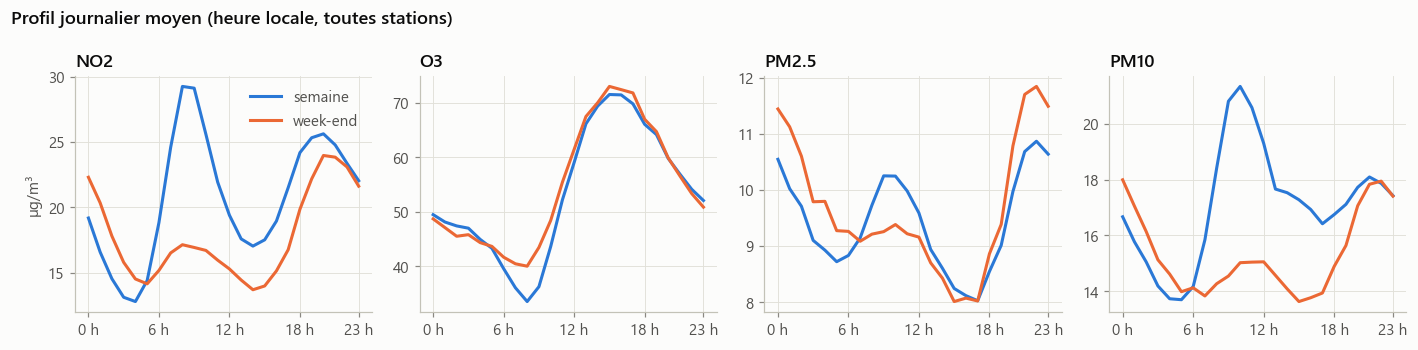

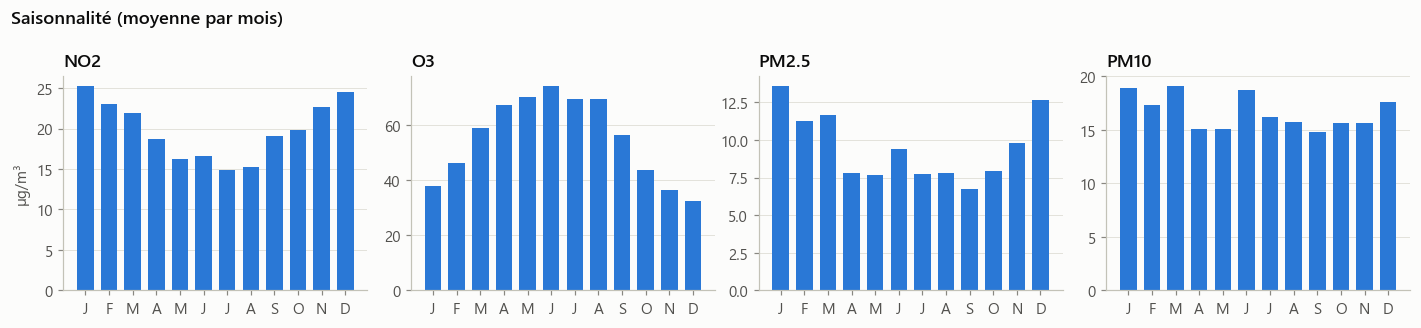

NO2 moyen : semaine 20.7 µg/m³, week-end 17.8 µg/m³


In [3]:
wk, we = a.hourly_profile(d, weekend=False), a.hourly_profile(d, weekend=True)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, p in zip(axes, ["no2", "o3", "pm25", "pm10"]):
    ax.plot(wk.index, wk[p], color=viz.BLUE, label="semaine")
    ax.plot(we.index, we[p], color=viz.ORANGE, label="week-end")
    ax.set_title(a.LABELS[p]); ax.set_xticks([0, 6, 12, 18, 23], ["0 h", "6 h", "12 h", "18 h", "23 h"])
axes[0].set_ylabel("µg/m³"); axes[0].legend()
fig.suptitle("Profil journalier moyen (heure locale, toutes stations)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.show()
mp = a.monthly_profile(d)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.0))
for ax, p in zip(axes, ["no2", "o3", "pm25", "pm10"]):
    ax.bar(mp.index, mp[p], color=viz.BLUE, width=0.7); ax.set_title(a.LABELS[p])
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND")); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("µg/m³")
fig.suptitle("Saisonnalité (moyenne par mois)", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout(); plt.show()
print(f"NO2 moyen : semaine {wk['no2'].mean():.1f} µg/m³, week-end {we['no2'].mean():.1f} µg/m³")

**Conclusion Q2.**
- Le **NO2** a un **double pic** aux heures de pointe du trafic (**8-9 h** et **19-21 h**, ≈ 29 µg/m³ contre 13 la
  nuit) et baisse d'environ **14 % le week-end** (20,7 → 17,8 µg/m³) : c'est la signature du trafic routier. Le CO
  suit le même rythme.
- L'**O3** a le profil inverse : minimum à 8 h, **maximum à 15-16 h** (≈ 71 µg/m³). L'ozone n'est pas émis
  directement : il **se forme sous l'effet du soleil** à partir des polluants du matin, et il est « consommé » par le
  NO2 aux heures de trafic.
- Les **PM2.5** montent **le soir et la nuit** (chauffage, couche d'air plus basse et stable). Les **PM10** ont un
  pic vers 10 h **uniquement les jours ouvrés** — leur courbe est plate le week-end : un indice d'origine liée à
  l'activité (remise en suspension des poussières par le trafic, chantiers).
- En saison : NO2, CO et PM2.5 sont **maximaux en hiver** (chauffage, inversions de température) ; l'O3 est
  **maximal en mai-août** (ensoleillement).

## Q3 — Polluants dominants par ville (comparaison aux seuils de l'OMS)

**Méthode** : rapport moyenne 5 ans / valeur guide **annuelle** de l'OMS (1 = au niveau de la valeur guide) ; et
part des jours où **au moins une station** de la ville dépasse la valeur guide **journalière**.

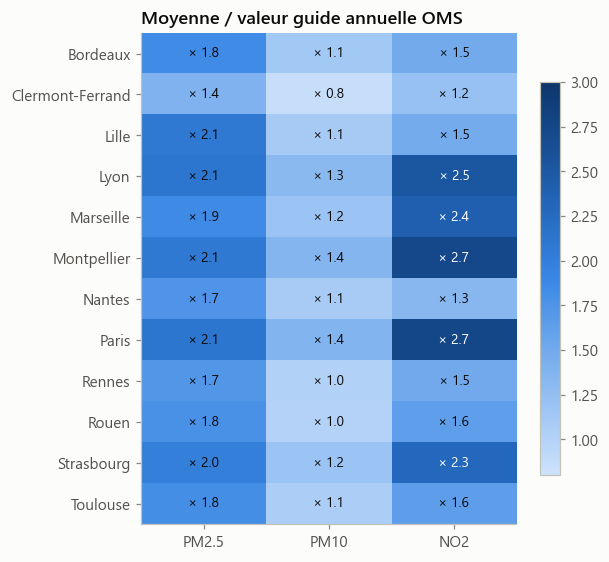

Polluant le plus au-dessus de sa valeur guide : {'bordeaux': 'PM2.5', 'clermont-ferrand': 'PM2.5', 'lille': 'PM2.5', 'lyon': 'NO2', 'marseille': 'NO2', 'montpellier': 'NO2', 'nantes': 'PM2.5', 'paris': 'NO2', 'rennes': 'PM2.5', 'rouen': 'PM2.5', 'strasbourg': 'NO2', 'toulouse': 'PM2.5'}


,% jours NO2 > 25,% jours PM2.5 > 15,% jours PM10 > 45,% jours O3 8h > 100
ville_id,,,,
bordeaux,28.1,15.6,2.2,13.8
clermont-ferrand,32.6,8.8,0.5,19.4
lille,34.0,24.8,2.6,10.9
lyon,91.0,21.8,5.0,17.2
marseille,60.5,15.4,1.8,24.0
montpellier,51.6,16.1,1.8,18.8
nantes,8.7,12.1,1.0,13.7
paris,88.3,24.0,3.7,14.4
rennes,20.5,13.1,1.7,12.4


In [4]:
r = a.who_ratio(st)
r.columns = [a.LABELS[c] for c in r.columns]
fig, ax = plt.subplots(figsize=(5.5, 5.8))
im = ax.imshow(r.values, cmap=viz.SEQUENTIAL, vmin=0.8, vmax=3, aspect="auto")
ax.set_xticks(range(r.shape[1]), r.columns); ax.set_yticks(range(len(r)), r.index.str.title()); ax.grid(False)
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        v = r.values[i, j]
        ax.text(j, i, f"× {v:.1f}", ha="center", va="center", fontsize=9, color="#ffffff" if v > 2.2 else viz.INK)
ax.set_title("Moyenne / valeur guide annuelle OMS")
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()
print("Polluant le plus au-dessus de sa valeur guide :", a.dominant_pollutant(a.who_ratio(st)).to_dict())
ex = a.exceedance_days(cday)
tab = ex.pivot(index="ville_id", columns="polluant", values="pct_jours")[["no2", "pm25", "pm10", "o3"]]
tab.columns = ["% jours NO2 > 25", "% jours PM2.5 > 15", "% jours PM10 > 45", "% jours O3 8h > 100"]
display(tab)

**Conclusion Q3.**
- **Les 12 villes dépassent les valeurs guides annuelles de l'OMS pour les PM2.5 (× 1,4 à × 2,1) et le NO2
  (× 1,2 à × 2,7)** ; pour les PM10, elles sont proches de la valeur guide (× 0,85 à Clermont-Ferrand à × 1,4 à
  Paris).
- **Polluant dominant** : le **NO2 dans les grandes agglomérations** (Paris × 2,7, Montpellier × 2,7, Lyon × 2,5,
  Marseille × 2,4, Strasbourg × 2,3) — un problème de **trafic** ; les **PM2.5 ailleurs** (Lille, Bordeaux,
  Toulouse, Nantes, Rennes, Rouen, Clermont-Ferrand) — une pollution de **fond**.
- En journalier, **Lyon (91 % des jours) et Paris (88 %)** ont presque chaque jour au moins une station au-dessus de
  25 µg/m³ de NO2 (stations de trafic) ; l'ozone dépasse la valeur guide 8 h **10 à 24 % des jours** (Marseille la
  plus touchée), surtout l'été.
- Les **moyennes de ville** restent sous les **valeurs limites annuelles européennes** actuelles (NO2 40, PM2.5 25,
  PM10 40 µg/m³), beaucoup moins strictes que les valeurs guides sanitaires de l'OMS ; mais **au bord des
  périphériques de Paris (43,9) et de Lyon (42,9), le NO2 dépasse même la valeur limite européenne**.

## Q4 — Épisodes de pollution anormaux

**Méthode** : (1) **épisodes collectifs** : jours où **au moins 4 villes** dépassent la valeur guide 24 h (moyenne
de la ville), regroupés en jours consécutifs ; (2) **pics anormaux** locaux : moyenne journalière > moyenne des 30
jours précédents + 3 écarts-types.

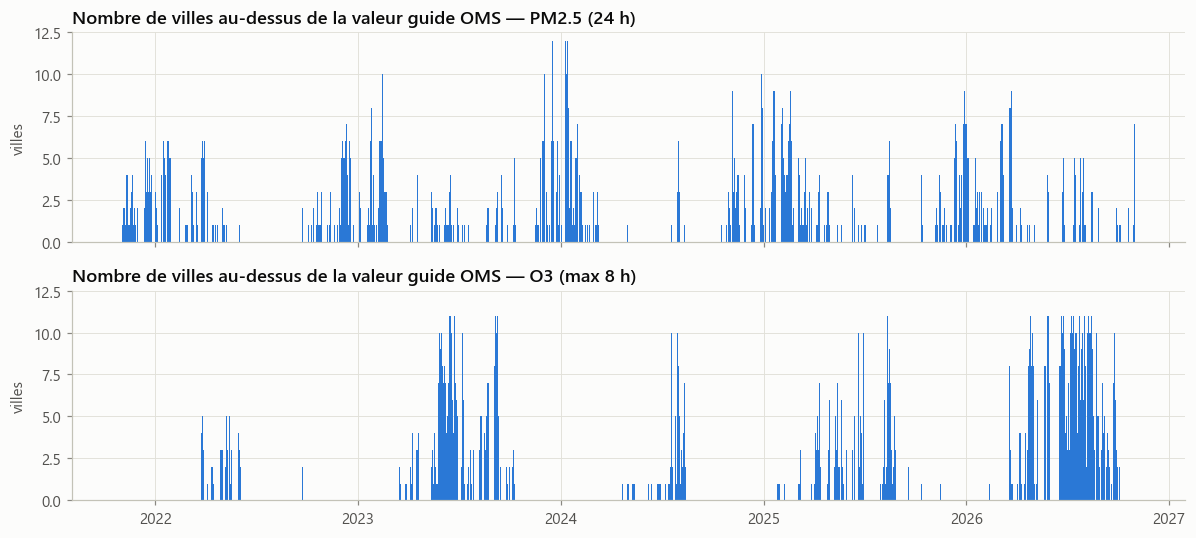

Épisodes collectifs PM2.5 (≥ 4 villes) : 81 — les plus étendus :


,debut,fin,jours,villes_max,pic_moyenne
0,09/01/2024,16/01/2024,8,12,49.6
1,16/12/2023,19/12/2023,4,12,49.7
2,18/01/2024,21/01/2024,4,11,48.1
3,08/02/2023,16/02/2023,9,10,55.2
4,29/11/2023,03/12/2023,5,10,29.0


Épisodes collectifs NO2 (≥ 4 villes) : 176 — les plus étendus :


,debut,fin,jours,villes_max,pic_moyenne
0,08/02/2023,18/02/2023,11,11,77.9
1,05/10/2023,12/10/2023,8,11,66.8
2,25/01/2024,31/01/2024,7,10,62.4
3,29/11/2023,03/12/2023,5,10,48.6
4,09/01/2024,23/01/2024,15,9,71.1


Épisodes collectifs O3 (≥ 4 villes) : 61 — les plus étendus :


,debut,fin,jours,villes_max,pic_moyenne
0,07/07/2026,26/07/2026,20,12,127.6
1,27/05/2026,31/05/2026,5,12,118.0
2,26/05/2023,29/06/2023,35,11,121.1
3,18/06/2026,01/07/2026,14,11,140.2
4,07/08/2026,19/08/2026,13,11,123.9


Pics anormaux de PM10 (> moyenne 30 j + 3 σ) : 343 jours ville — les plus forts :


,ville_id,date,moyenne,ref,z
31485,nantes,06/09/2023,74.8,9.5,19.0
39966,rennes,05/09/2023,56.3,10.1,17.9
31615,nantes,02/02/2024,144.3,18.6,16.2
3495,bordeaux,14/11/2025,46.1,10.0,13.8
55268,toulouse,14/11/2025,64.7,14.1,11.0
25260,marseille,27/08/2026,77.7,20.6,10.6


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, p, lim in ((axes[0], "pm25", a.WHO_DAILY["pm25"]), (axes[1], "o3", a.WHO_O3_8H)):
    g = cday[cday["polluant"] == p]
    over = g[(g["o3_8h"] > lim) if p == "o3" else (g["moyenne"] > lim)].groupby("date")["ville_id"].nunique()
    ax.bar(over.index, over.values, width=1.0, color=viz.BLUE)
    ax.set_ylabel("villes"); ax.set_ylim(0, 12.5)
    ax.set_title(f"Nombre de villes au-dessus de la valeur guide OMS — {a.LABELS[p]}"
                 + (" (max 8 h)" if p == "o3" else " (24 h)"))
plt.tight_layout(); plt.show()
for p in ("pm25", "no2", "o3"):
    e = a.episodes(cday, p)
    print(f"Épisodes collectifs {a.LABELS[p]} (≥ 4 villes) : {len(e)} — les plus étendus :")
    display(e.head(5).assign(debut=e["debut"].dt.strftime("%d/%m/%Y"), fin=e["fin"].dt.strftime("%d/%m/%Y")))
an = a.anomalies(cday, "pm10")
print(f"Pics anormaux de PM10 (> moyenne 30 j + 3 σ) : {len(an)} jours ville — les plus forts :")
display(an.head(6).assign(date=an["date"].dt.strftime("%d/%m/%Y")))

**Conclusion Q4.**
- **Particules fines (PM2.5) : épisodes d'hiver**. Les plus étendus touchent les 12 villes en même temps, du
  **9 au 16 janvier 2024**, du 16 au 19 décembre 2023, et 10 villes en février 2023 (jusqu'à 55 µg/m³ en moyenne de
  ville) : chauffage combiné à un temps anticyclonique froid et sans vent, qui bloque les polluants.
- **NO2** : épisodes eux aussi hivernaux et longs (8 au 18 février 2023, 11 villes), les mêmes périodes que les PM2.5.
- **Ozone : épisodes d'été, qui coïncident avec les vagues de chaleur de la partie P1** — les 12 villes du **7 au 26
  juillet 2026** et du 27 au 31 mai 2026, et 35 jours (11 villes) en mai-juin 2023. Le lien chaleur → ozone sera
  quantifié en P4.
- Des **pics anormaux de PM10 très localisés** existent (Nantes 75 µg/m³ le 06/09/2023 pour une moyenne de 10 ;
  Clermont-Ferrand 97 µg/m³ le 11/10/2023) ; leur cause (poussières, incendies, chantiers…) **ne peut pas être
  identifiée** avec nos données.
- *Attention* : la frise montre peu d'épisodes en 2022. C'est **en partie un effet des trous de l'archive OpenAQ**
  sur 2021-2023 (couverture de 58 à 90 %), pas forcément un air plus propre : on ne compare donc pas le nombre
  d'épisodes d'une année à l'autre.

## Synthèse P3

| Question | Réponse |
|---|---|
| Zones les plus polluées | bords des grands axes (périphériques de Paris et Lyon, A35, A7) ; NO2 : Paris, Montpellier, Lyon, Marseille |
| Variation journalière | NO2 et CO : pics 8-9 h et 19-21 h, −14 % le week-end ; O3 : maximum 15-16 h ; PM2.5 : soir et nuit |
| Polluants dominants | NO2 dans les grandes agglomérations, PM2.5 ailleurs ; les 12 villes au-dessus des valeurs guides OMS PM2.5 et NO2 |
| Épisodes | PM2.5 et NO2 en hiver (janvier 2024 : 12 villes) ; O3 en été, pendant les vagues de chaleur (juillet 2026 : 12 villes) |

*Limites* : couverture incomplète en 2021-2023 (archive OpenAQ) ; CO mesuré dans 6 villes seulement ; type de station
déduit du nom ; la moyenne d'une ville dépend de la localisation de ses quelques stations (3 à 5).